# Team 12 — Noise Investigation

**Research Question:** How does noisy data affect ML generalization?

**Dataset:** HTRU2 pulsar classification  
**Models:** Logistic Regression and K-Nearest Neighbors (KNN)

This is the compact final supporting-evidence notebook. It keeps the complete investigation required by the course while removing duplicate analysis and unnecessary code.

## Project evidence checklist
- Research question and hypothesis stated
- ML theory connection stated
- HTRU2 dataset and suitability described
- Controlled feature-noise and label-noise experiments
- Clean fixed test set; training data only are corrupted
- 7 feature-noise levels and 6 label-noise levels
- 10 random repetitions per condition
- Logistic Regression and KNN evaluated consistently
- Quantitative metrics: Accuracy, Precision, Recall, F1, ROC-AUC
- Multiple tables/figures and a 10% feature-vs-label comparison
- Transition analysis for 6–10% label noise
- Confusion-matrix evidence and minority-class interpretation
- Limitations and conclusion included
- Raw and summary CSV results saved



## 1. Research Question, Hypothesis and ML Theory

**Research question:** How does noisy data affect ML generalization?

**Hypotheses**
- Feature noise will cause a gradual and relatively mild decline because the training labels remain correct.
- Label noise will cause a stronger decline because the training targets themselves become incorrect.
- On the imbalanced HTRU2 dataset, increasing symmetric label noise will increasingly damage the minority pulsar signal.
- Logistic Regression and KNN may respond differently because they use different learning mechanisms.

**Theory**
- Logistic Regression learns a linear decision boundary.
- KNN predicts from nearby training examples, so corrupted examples can affect local neighbourhoods.
- Feature noise changes the inputs while the target remains correct.
- Label noise changes the target, so the supervision becomes unreliable.
- Generalization is evaluated on a clean test set that is never corrupted.

## 2. Dataset and Experimental Design

**Dataset justification:** HTRU2 is a public binary classification dataset with fully numeric features and strong class imbalance. This makes it suitable for controlled noise experiments and makes F1-score important alongside accuracy and ROC-AUC.

**Controls**
- 80/20 stratified train/test split, `random_state=42`
- Test set fixed and clean throughout
- Same two models at every noise level
- 10 repetitions per condition using different seeds
- At 0% noise, repetitions are identical because no perturbation is added

**Conditions**
- Feature noise: 0, 2, 5, 10, 15, 20, 30%
- Label noise: 0, 2, 4, 6, 8, 10%
- Transition diagnostic: 6, 8, 8.5, 9, 9.5, 10%
- Metrics: Accuracy, Precision, Recall, F1, ROC-AUC

In [ ]:
!pip install ucimlrepo

In [ ]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
from IPython.display import display


In [ ]:
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
FIGURES_DIR = REPO_ROOT / "figures"
RESULTS_DIR = REPO_ROOT / "results"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Figures ->", FIGURES_DIR)
print("Results ->", RESULTS_DIR)

Figures -> /content/figures
Results -> /content/results


In [ ]:
# ============================================================
# 3. EXPERIMENT CONFIGURATION
# ============================================================
RANDOM_STATE = 42

# Feature-noise levels
FEATURE_NOISE_LEVELS = [
    0.00,
    0.02,
    0.05,
    0.10,
    0.15,
    0.20,
    0.30
]

# Label-noise levels
#
# Symmetric label noise preserves the original class distribution exactly.
#
# The label-noise range is limited to 10% for the controlled experiment.
#
LABEL_NOISE_LEVELS = [
    0.00,
    0.02,
    0.04,
    0.06,
    0.08,
    0.10
]

# Number of repetitions per condition
N_REPETITIONS = 10

# Test-set proportion
TEST_SIZE = 0.20


def format_noise_percent(level):
    """Keep 8.5% distinct from 8% (do not truncate with int())."""
    pct = level * 100
    rounded = round(pct, 1)
    if abs(rounded - round(rounded)) < 1e-9:
        return f"{int(round(rounded))}%"
    return f"{rounded:.1f}%"


print("=" * 80)
print("NOISE INVESTIGATION")
print("=" * 80)

print("\nFeature noise levels:")
print(
    [format_noise_percent(x) for x in FEATURE_NOISE_LEVELS]
)

print("\nLabel noise levels:")
print(
    [format_noise_percent(x) for x in LABEL_NOISE_LEVELS]
)

print(
    "\nRepetitions per condition:",
    N_REPETITIONS
)

NOISE INVESTIGATION

Feature noise levels:
['0%', '2%', '5%', '10%', '15%', '20%', '30%']

Label noise levels:
['0%', '2%', '4%', '6%', '8%', '10%']

Repetitions per condition: 10


In [ ]:
!pip install -q ucimlrepo
from ucimlrepo import fetch_ucirepo
import pandas as pd

print("\n" + "=" * 80)
print("[4] LOADING HTRU2 DATASET")
print("=" * 80)

htru2 = fetch_ucirepo(id=372)

X = htru2.data.features.copy()
y = htru2.data.targets.copy()

# Convert target DataFrame to Series
if isinstance(y, pd.DataFrame):
    y = y.iloc[:, 0]

# Reset indices
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

print("\nDataset shape:")
print("X:", X.shape)
print("y:", y.shape)

print("\nFeature names:")
print(list(X.columns))

print("\nFirst 5 rows of features (head):")
display(X.head())


[4] LOADING HTRU2 DATASET

Dataset shape:
X: (17898, 8)
y: (17898,)

Feature names:
['Profile_mean', 'Profile_stdev', 'Profile_skewness', 'Profile_kurtosis', 'DM_mean', 'DM_stdev', 'DM_skewness', 'DM_kurtosis']

First 5 rows of features (head):


,Profile_mean,Profile_stdev,Profile_skewness,Profile_kurtosis,DM_mean,DM_stdev,DM_skewness,DM_kurtosis
0,140.562500,55.683782,-0.234571,-0.699648,3.199833,19.110426,7.975532,74.242225
1,102.507812,58.882430,0.465318,-0.515088,1.677258,14.860146,10.576487,127.393580
2,103.015625,39.341649,0.323328,1.051164,3.121237,21.744669,7.735822,63.171909
3,136.750000,57.178449,-0.068415,-0.636238,3.642977,20.959280,6.896499,53.593661
4,88.726562,40.672225,0.600866,1.123492,1.178930,11.468720,14.269573,252.567306


In [ ]:
# ============================================================
# 5. TRAIN/TEST SPLIT
# ============================================================
print("\n" + "=" * 80)
print("[5] TRAIN / TEST SPLIT")
print("=" * 80)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

# Reset indices to maintain explicit X/y alignment.
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(
    "\nTraining samples:",
    len(X_train)
)

print(
    "Testing samples :",
    len(X_test)
)

print("\nTraining class distribution:")
print(
    y_train.value_counts()
    .sort_index()
)

print("\nTesting class distribution:")
print(
    y_test.value_counts()
    .sort_index()
)


[5] TRAIN / TEST SPLIT

Training samples: 14318
Testing samples : 3580

Training class distribution:
class
0    13007
1     1311
Name: count, dtype: int64

Testing class distribution:
class
0    3252
1     328
Name: count, dtype: int64


In [ ]:
# ============================================================
# 6. DEFINE MODELS
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])
}

print("Models:")
for name in models:
    print("-", name)


Models:
- Logistic Regression
- KNN


In [ ]:
# ============================================================
# 7. FEATURE-NOISE PROCEDURE
# ============================================================
def add_feature_noise(
    X_data,
    noise_level,
    random_state
):
    """
    Add zero-mean Gaussian perturbations independently to the training features.

    For feature j:

        X_noisy[j] =
            X[j] + alpha * std(X[j]) * epsilon

    where:

        epsilon ~ N(0, 1)

    The perturbation scale is therefore relative to the natural
    scale of each feature.
    """

    rng = np.random.default_rng(
        random_state
    )

    X_noisy = X_data.copy()

    for column in X_noisy.columns:

        feature_std = X_data[column].std()

        noise = rng.normal(
            loc=0,
            scale=(
                noise_level
                * feature_std
            ),
            size=len(X_data)
        )

        X_noisy[column] = (
            X_noisy[column]
            + noise
        )

    return X_noisy

In [ ]:
# ============================================================
# 8. SYMMETRIC LABEL-NOISE PROCEDURE
# ============================================================
def add_symmetric_label_noise(
    y_data,
    noise_level,
    random_state
):
    """
    Apply symmetric label noise while preserving
    the training class counts exactly.

    If the requested noise level is p:

        total labels corrupted ≈ p * N

    Half of the corrupted labels go:

        0 -> 1

    and half:

        1 -> 0

    Since the same number move in each direction,
    the final class distribution is unchanged.

    Because HTRU2 is class-imbalanced, the feasible range of
    symmetric label noise is constrained by the minority class size.
    """

    rng = np.random.default_rng(
        random_state
    )

    y_noisy = (
        y_data
        .copy()
        .reset_index(drop=True)
    )

    # Identify the two classes
    class_0_indices = np.where(
        y_noisy.values == 0
    )[0]

    class_1_indices = np.where(
    y_noisy.values == 1)[0]
    # Determine the requested number of label flips
    total_requested = int(
        round(
            noise_level
            * len(y_noisy)
        )
    )

    # Use equal numbers of flips in each direction
    flips_each_direction = (
        total_requested // 2
    )

    # Confirm that the minority class can support the requested flips.
    if flips_each_direction > len(
        class_1_indices
    ):

        raise ValueError(
            f"Noise level "
            f"{noise_level * 100:.2f}% "
            f"is too high to preserve "
            f"class proportions."
        )

    # Randomly select class-0 samples
    zero_to_one = rng.choice(
        class_0_indices,
        size=flips_each_direction,
        replace=False
    )

    # Randomly select class-1 samples
    one_to_zero = rng.choice(
        class_1_indices,
        size=flips_each_direction,
        replace=False
    )

    # Apply the label flips
    y_noisy.iloc[
        zero_to_one
    ] = 1

    y_noisy.iloc[
        one_to_zero
    ] = 0

    return y_noisy.astype(int)

In [ ]:
# ============================================================
# 9. MODEL EVALUATION
# ============================================================

def evaluate_model(model, X_train_data, y_train_data, X_test_data, y_test_data):
    model.fit(X_train_data, y_train_data)
    y_pred = model.predict(X_test_data)

    results = {
        "Accuracy": accuracy_score(y_test_data, y_pred),
        "Precision": precision_score(y_test_data, y_pred, zero_division=0),
        "Recall": recall_score(y_test_data, y_pred, zero_division=0),
        "F1": f1_score(y_test_data, y_pred, zero_division=0)
    }

    if hasattr(model, "predict_proba"):
        results["ROC-AUC"] = roc_auc_score(
            y_test_data, model.predict_proba(X_test_data)[:, 1]
        )
    else:
        results["ROC-AUC"] = np.nan

    return results


In [ ]:
# ============================================================
# 11. CLEAN BASELINE
# ============================================================
print("\n" + "=" * 80)
print("[11] CLEAN BASELINE")
print("=" * 80)

baseline_results = []

for model_name, model in models.items():

    results = evaluate_model(
        model,
        X_train,
        y_train,
        X_test,
        y_test
    )

    baseline_results.append({

        "Model":
            model_name,

        **results
    })

baseline_df = pd.DataFrame(
    baseline_results
)

print("\nClean baseline performance:")

display(
    baseline_df.round(4)
)


[11] CLEAN BASELINE

Clean baseline performance:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9796,0.9443,0.8262,0.8813,0.9710
1,KNN,0.9804,0.9329,0.8476,0.8882,0.9516


In [ ]:
# ============================================================
# 12. FEATURE-NOISE EXPERIMENT
# ============================================================

import time

feature_results = []

total_runs = len(FEATURE_NOISE_LEVELS) * N_REPETITIONS * len(models)
run_number = 0

print("=" * 70)
print("FEATURE NOISE EXPERIMENT")
print("=" * 70)
print(f"Noise levels : {[f'{x*100:g}%' for x in FEATURE_NOISE_LEVELS]}")
print(f"Repetitions  : {N_REPETITIONS}")
print(f"Models       : {list(models.keys())}")
print(f"Total model trainings: {total_runs}")
print("=" * 70)

experiment_start = time.time()

for noise_level in FEATURE_NOISE_LEVELS:

    print(f"\n{'=' * 70}")
    print(f"FEATURE NOISE LEVEL: {noise_level * 100:g}%")
    print(f"{'=' * 70}")

    level_start = time.time()

    for repetition in range(N_REPETITIONS):

        seed = RANDOM_STATE + repetition + int(noise_level * 10000)

        print(
            f"\n  Repetition {repetition + 1}/{N_REPETITIONS} "
            f"| Seed: {seed}"
        )
        print("  Creating noisy training data...")

        X_train_noisy = add_feature_noise(
            X_train,
            noise_level,
            random_state=seed
        )

        print("  Noisy training data created.")

        for model_name, model in models.items():

            run_number += 1
            model_start = time.time()

            print(
                f"    [{run_number}/{total_runs}] "
                f"Training {model_name}..."
            )

            results = evaluate_model(
                model,
                X_train_noisy,
                y_train,
                X_test,
                y_test
            )

            model_time = time.time() - model_start

            feature_results.append({
                "Noise_Type": "Feature Noise",
                "Noise_Level": noise_level,
                "Noise_Percentage": noise_level * 100,
                "Repetition": repetition + 1,
                "Seed": seed,
                "Model": model_name,
                **results
            })

            print(
                f"    ✓ {model_name} completed "
                f"({model_time:.2f}s) | "
                f"Accuracy={results['Accuracy']:.4f} | "
                f"F1={results['F1']:.4f} | "
                f"ROC-AUC={results['ROC-AUC']:.4f}"
            )

        print(
            f"  ✓ Repetition {repetition + 1}/{N_REPETITIONS} completed "
            f"({time.time() - level_start:.2f}s for this noise level)"
        )

    print(
        f"✓ {noise_level * 100:g}% noise completed "
        f"({time.time() - level_start:.2f}s)"
    )

feature_results_df = pd.DataFrame(feature_results)

print("\n" + "=" * 70)
print("FEATURE NOISE EXPERIMENT COMPLETED")
print("=" * 70)
print(f"Rows generated: {len(feature_results_df)}")
print(f"Total time: {time.time() - experiment_start:.2f}s")
print("=" * 70)

FEATURE NOISE EXPERIMENT
Noise levels : ['0%', '2%', '5%', '10%', '15%', '20%', '30%']
Repetitions  : 10
Models       : ['Logistic Regression', 'KNN']
Total model trainings: 140

FEATURE NOISE LEVEL: 0%

  Repetition 1/10 | Seed: 42
  Creating noisy training data...
  Noisy training data created.
    [1/140] Training Logistic Regression...
    ✓ Logistic Regression completed (0.22s) | Accuracy=0.9796 | F1=0.8813 | ROC-AUC=0.9710
    [2/140] Training KNN...
    ✓ KNN completed (0.26s) | Accuracy=0.9804 | F1=0.8882 | ROC-AUC=0.9516
  ✓ Repetition 1/10 completed (0.50s for this noise level)

  Repetition 2/10 | Seed: 43
  Creating noisy training data...
  Noisy training data created.
    [3/140] Training Logistic Regression...
    ✓ Logistic Regression completed (0.05s) | Accuracy=0.9796 | F1=0.8813 | ROC-AUC=0.9710
    [4/140] Training KNN...
    ✓ KNN completed (0.36s) | Accuracy=0.9804 | F1=0.8882 | ROC-AUC=0.9516
  ✓ Repetition 2/10 completed (0.92s for this noise level)

  Repetition

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


    ✓ KNN completed (0.53s) | Accuracy=0.9804 | F1=0.8882 | ROC-AUC=0.9530
  ✓ Repetition 10/10 completed (8.04s for this noise level)
✓ 5% noise completed (8.04s)

FEATURE NOISE LEVEL: 10%

  Repetition 1/10 | Seed: 1042
  Creating noisy training data...
  Noisy training data created.
    [61/140] Training Logistic Regression...
    ✓ Logistic Regression completed (0.18s) | Accuracy=0.9793 | F1=0.8791 | ROC-AUC=0.9707
    [62/140] Training KNN...
    ✓ KNN completed (0.54s) | Accuracy=0.9810 | F1=0.8910 | ROC-AUC=0.9466
  ✓ Repetition 1/10 completed (0.73s for this noise level)

  Repetition 2/10 | Seed: 1043
  Creating noisy training data...
  Noisy training data created.
    [63/140] Training Logistic Regression...
    ✓ Logistic Regression completed (0.19s) | Accuracy=0.9793 | F1=0.8787 | ROC-AUC=0.9714
    [64/140] Training KNN...
    ✓ KNN completed (0.70s) | Accuracy=0.9802 | F1=0.8868 | ROC-AUC=0.9486
  ✓ Repetition 2/10 completed (1.64s for this noise level)

  Repetition 3/10

In [ ]:
# ============================================================
# 13. LABEL-NOISE EXPERIMENT
# ============================================================

label_results = []

total_runs = len(LABEL_NOISE_LEVELS) * N_REPETITIONS * len(models)
run_number = 0

print("=" * 70)
print("LABEL NOISE EXPERIMENT")
print("=" * 70)
print(f"Noise levels : {[f'{x*100:g}%' for x in LABEL_NOISE_LEVELS]}")
print(f"Repetitions  : {N_REPETITIONS}")
print(f"Models       : {list(models.keys())}")
print(f"Total model trainings: {total_runs}")
print("=" * 70)

experiment_start = time.time()

for noise_level in LABEL_NOISE_LEVELS:

    print(f"\n{'=' * 70}")
    print(f"LABEL NOISE LEVEL: {noise_level * 100:g}%")
    print(f"{'=' * 70}")

    level_start = time.time()

    for repetition in range(N_REPETITIONS):

        seed = RANDOM_STATE + repetition + int(noise_level * 10000)

        print(
            f"\n  Repetition {repetition + 1}/{N_REPETITIONS} "
            f"| Seed: {seed}"
        )
        print("  Creating noisy training labels...")

        y_train_noisy = add_symmetric_label_noise(
            y_train,
            noise_level,
            random_state=seed
        )

        flipped = (y_train_noisy.values != y_train.values).sum()

        print(
            f"  Noisy labels created | "
            f"Labels changed: {flipped}/{len(y_train)}"
        )

        for model_name, model in models.items():

            run_number += 1
            model_start = time.time()

            print(
                f"    [{run_number}/{total_runs}] "
                f"Training {model_name}..."
            )

            results = evaluate_model(
                model,
                X_train,
                y_train_noisy,
                X_test,
                y_test
            )

            model_time = time.time() - model_start

            label_results.append({
                "Noise_Type": "Label Noise",
                "Noise_Level": noise_level,
                "Noise_Percentage": noise_level * 100,
                "Repetition": repetition + 1,
                "Seed": seed,
                "Model": model_name,
                "Actual_Flipped": int(flipped),
                "Train_Class_0": int((y_train_noisy == 0).sum()),
                "Train_Class_1": int((y_train_noisy == 1).sum()),
                **results
            })

            print(
                f"    ✓ {model_name} completed "
                f"({model_time:.2f}s) | "
                f"Accuracy={results['Accuracy']:.4f} | "
                f"F1={results['F1']:.4f} | "
                f"ROC-AUC={results['ROC-AUC']:.4f}"
            )

        print(
            f"  ✓ Repetition {repetition + 1}/{N_REPETITIONS} completed "
            f"({time.time() - level_start:.2f}s for this noise level)"
        )

    print(
        f"✓ {noise_level * 100:g}% noise completed "
        f"({time.time() - level_start:.2f}s)"
    )

label_results_df = pd.DataFrame(label_results)

print("\n" + "=" * 70)
print("LABEL NOISE EXPERIMENT COMPLETED")
print("=" * 70)
print(f"Rows generated: {len(label_results_df)}")
print(f"Total time: {time.time() - experiment_start:.2f}s")
print("=" * 70)

LABEL NOISE EXPERIMENT
Noise levels : ['0%', '2%', '4%', '6%', '8%', '10%']
Repetitions  : 10
Models       : ['Logistic Regression', 'KNN']
Total model trainings: 120

LABEL NOISE LEVEL: 0%

  Repetition 1/10 | Seed: 42
  Creating noisy training labels...
  Noisy labels created | Labels changed: 0/14318
    [1/120] Training Logistic Regression...
    ✓ Logistic Regression completed (0.06s) | Accuracy=0.9796 | F1=0.8813 | ROC-AUC=0.9710
    [2/120] Training KNN...
    ✓ KNN completed (0.24s) | Accuracy=0.9804 | F1=0.8882 | ROC-AUC=0.9516
  ✓ Repetition 1/10 completed (0.30s for this noise level)

  Repetition 2/10 | Seed: 43
  Creating noisy training labels...
  Noisy labels created | Labels changed: 0/14318
    [3/120] Training Logistic Regression...
    ✓ Logistic Regression completed (0.05s) | Accuracy=0.9796 | F1=0.8813 | ROC-AUC=0.9710
    [4/120] Training KNN...
    ✓ KNN completed (0.23s) | Accuracy=0.9804 | F1=0.8882 | ROC-AUC=0.9516
  ✓ Repetition 2/10 completed (0.59s for this

In [ ]:
# Combine feature-noise and label-noise results for summary analysis
all_results_df = pd.concat(
    [feature_results_df, label_results_df],
    ignore_index=True
)

print(f"Combined experimental rows: {len(all_results_df)}")
print(f"Expected rows: {len(FEATURE_NOISE_LEVELS) * N_REPETITIONS * len(models) + len(LABEL_NOISE_LEVELS) * N_REPETITIONS * len(models)}")


Combined experimental rows: 260
Expected rows: 260


In [ ]:
# ============================================================
# 14. SUMMARY STATISTICS
# ============================================================
print("\n" + "=" * 80)
print("[14] SUMMARY STATISTICS")
print("=" * 80)

flat_summary = (
    all_results_df
    .groupby(
        [
            "Noise_Type",
            "Noise_Level",
            "Model"
        ]
    )
    .agg(

        Accuracy_Mean=(
            "Accuracy",
            "mean"
        ),

        Accuracy_SD=(
            "Accuracy",
            "std"
        ),

        Precision_Mean=(
            "Precision",
            "mean"
        ),

        Precision_SD=(
            "Precision",
            "std"
        ),

        Recall_Mean=(
            "Recall",
            "mean"
        ),

        Recall_SD=(
            "Recall",
            "std"
        ),

        F1_Mean=(
            "F1",
            "mean"
        ),

        F1_SD=(
            "F1",
            "std"
        ),

        ROC_AUC_Mean=(
            "ROC-AUC",
            "mean"
        ),

        ROC_AUC_SD=(
            "ROC-AUC",
            "std"
        ),

        N=(
            "F1",
            "count"
        )
    )
    .reset_index()
)

flat_summary[
    "Noise_Percentage"
] = (
    flat_summary[
        "Noise_Level"
    ]
    * 100
)

print(
    "\nMean ± standard deviation:"
)

display(
    flat_summary
    .sort_values(
        [
            "Noise_Type",
            "Noise_Level",
            "Model"
        ]
    )
    [
        [
            "Noise_Type",
            "Noise_Percentage",
            "Model",
            "F1_Mean",
            "F1_SD",
            "ROC_AUC_Mean",
            "ROC_AUC_SD"
        ]
    ]
    .round(4)
)


[14] SUMMARY STATISTICS

Mean ± standard deviation:


,Noise_Type,Noise_Percentage,Model,F1_Mean,F1_SD,ROC_AUC_Mean,ROC_AUC_SD
0,Feature Noise,0.0,KNN,0.8882,0.0000,0.9516,0.0000
1,Feature Noise,0.0,Logistic Regression,0.8813,0.0000,0.9710,0.0000
2,Feature Noise,2.0,KNN,0.8885,0.0027,0.9513,0.0014
3,Feature Noise,2.0,Logistic Regression,0.8804,0.0013,0.9710,0.0001
4,Feature Noise,5.0,KNN,0.8874,0.0040,0.9521,0.0016
5,Feature Noise,5.0,Logistic Regression,0.8791,0.0012,0.9711,0.0002
6,Feature Noise,10.0,KNN,0.8874,0.0037,0.9483,0.0038
7,Feature Noise,10.0,Logistic Regression,0.8790,0.0010,0.9708,0.0004
8,Feature Noise,15.0,KNN,0.8856,0.0040,0.9469,0.0034
9,Feature Noise,15.0,Logistic Regression,0.8770,0.0020,0.9705,0.0004


In [ ]:
# Create model-wise summary tables used by the final figures
feature_summary = (
    flat_summary[flat_summary["Noise_Type"] == "Feature Noise"]
    .copy()
)
label_summary = (
    flat_summary[flat_summary["Noise_Type"] == "Label Noise"]
    .copy()
)

print("Feature summary rows:", len(feature_summary))
print("Label summary rows:", len(label_summary))


Feature summary rows: 14
Label summary rows: 12


In [ ]:
# ============================================================
# 15. CLEAN-BASELINE RESULTS
# ============================================================
baseline_f1 = (
    baseline_df[
        [
            "Model",
            "F1",
            "ROC-AUC"
        ]
    ]
    .rename(
        columns={
            "F1":
                "Baseline_F1",

            "ROC-AUC":
                "Baseline_ROC_AUC"
        }
    )
)


[16] RELATIVE F1 DEGRADATION


,Noise_Type,Noise_Percentage,Model,Baseline_F1,F1_Mean,F1_SD,F1_Degradation_Percent
0,Feature Noise,0.0,KNN,0.8882,0.8882,0.0000,0.0000
1,Feature Noise,0.0,Logistic Regression,0.8813,0.8813,0.0000,0.0000
2,Feature Noise,2.0,KNN,0.8882,0.8885,0.0027,-0.0358
3,Feature Noise,2.0,Logistic Regression,0.8813,0.8804,0.0013,0.1034
4,Feature Noise,5.0,KNN,0.8882,0.8874,0.0040,0.0921
5,Feature Noise,5.0,Logistic Regression,0.8813,0.8791,0.0012,0.2470
6,Feature Noise,10.0,KNN,0.8882,0.8874,0.0037,0.0893
7,Feature Noise,10.0,Logistic Regression,0.8813,0.8790,0.0010,0.2667
8,Feature Noise,15.0,KNN,0.8882,0.8856,0.0040,0.2950
9,Feature Noise,15.0,Logistic Regression,0.8813,0.8770,0.0020,0.4833


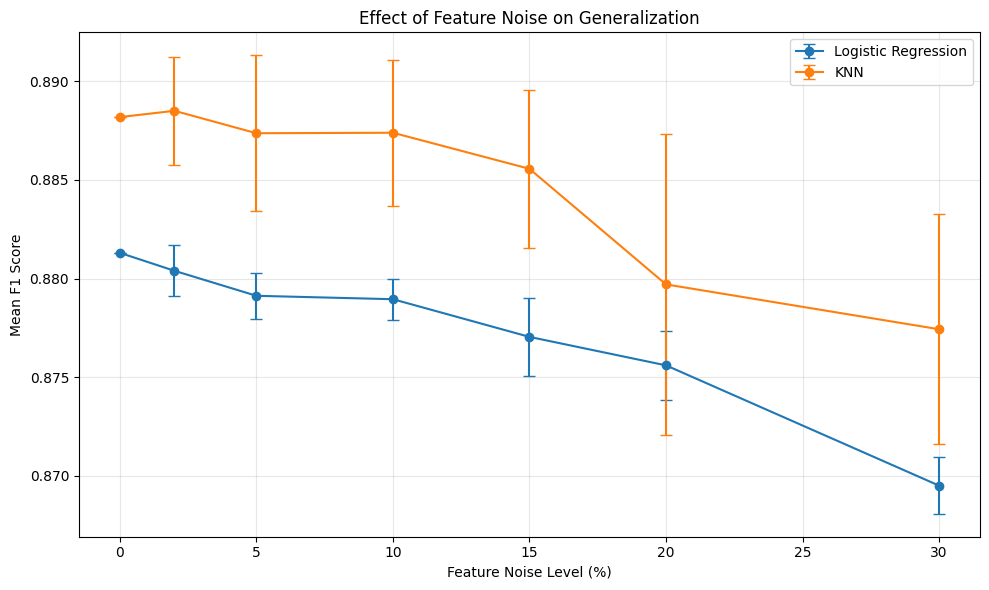

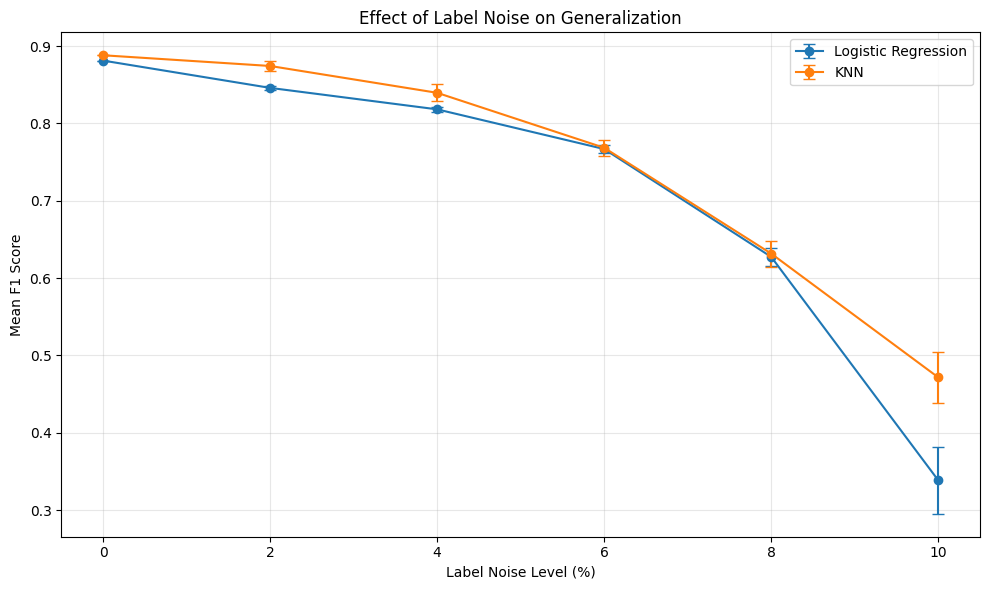

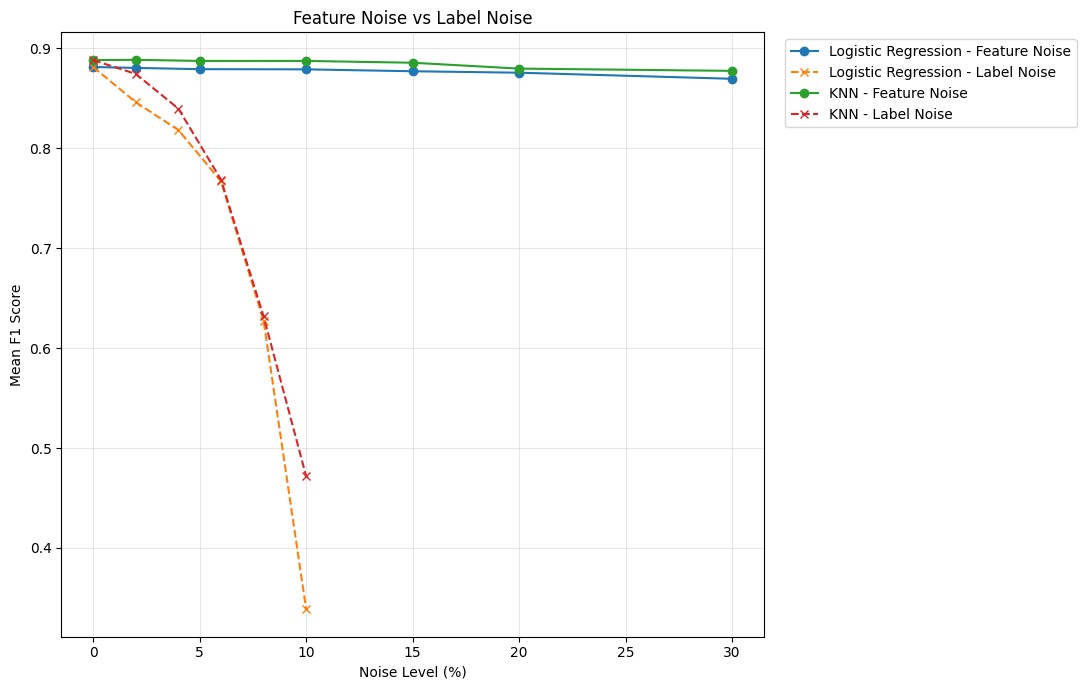

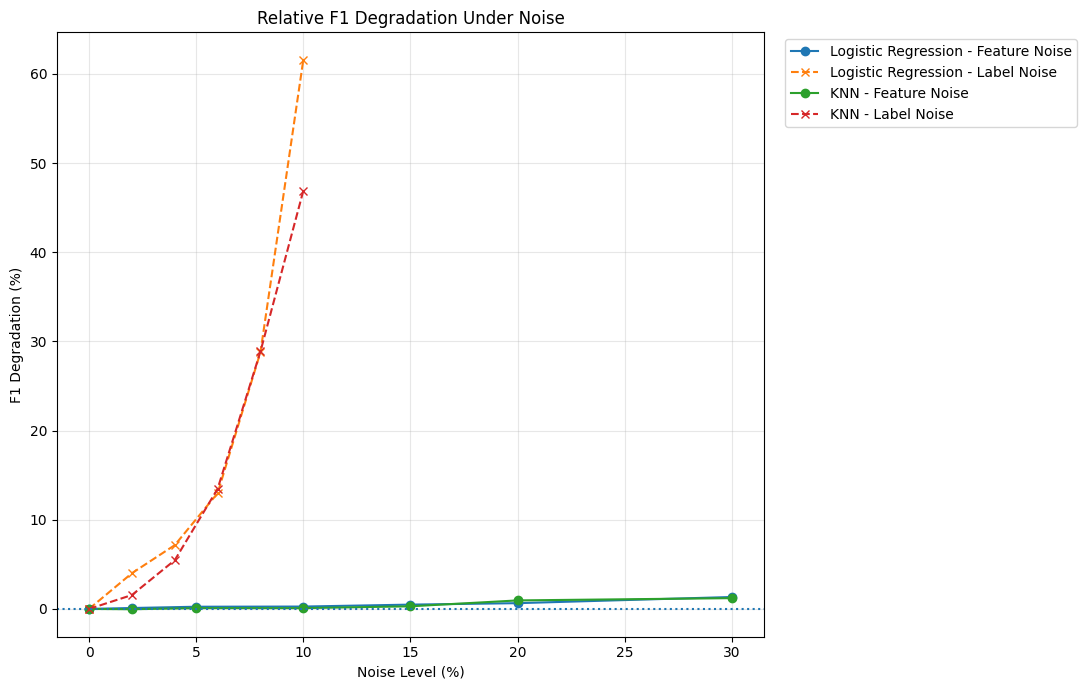

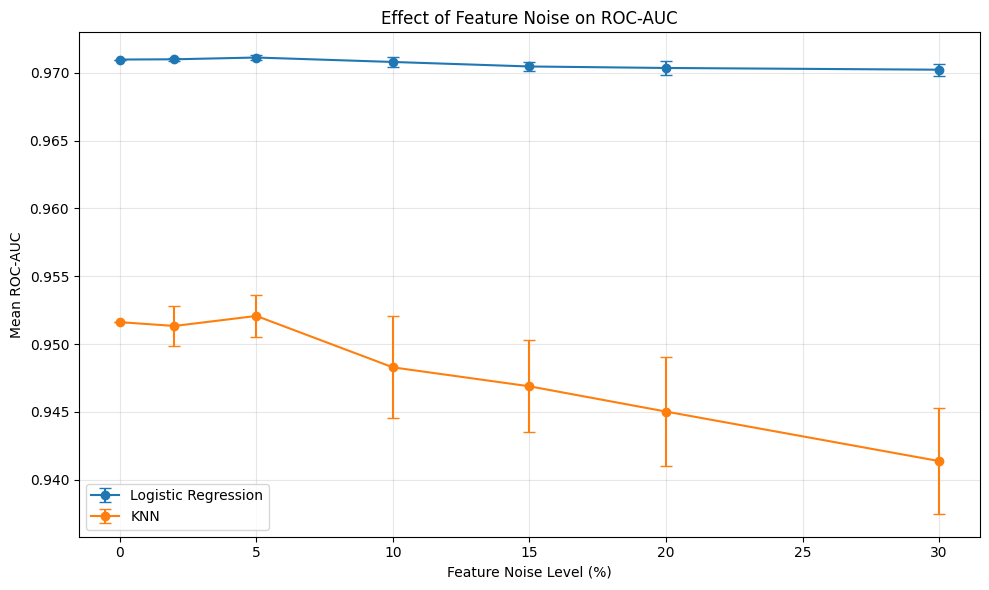

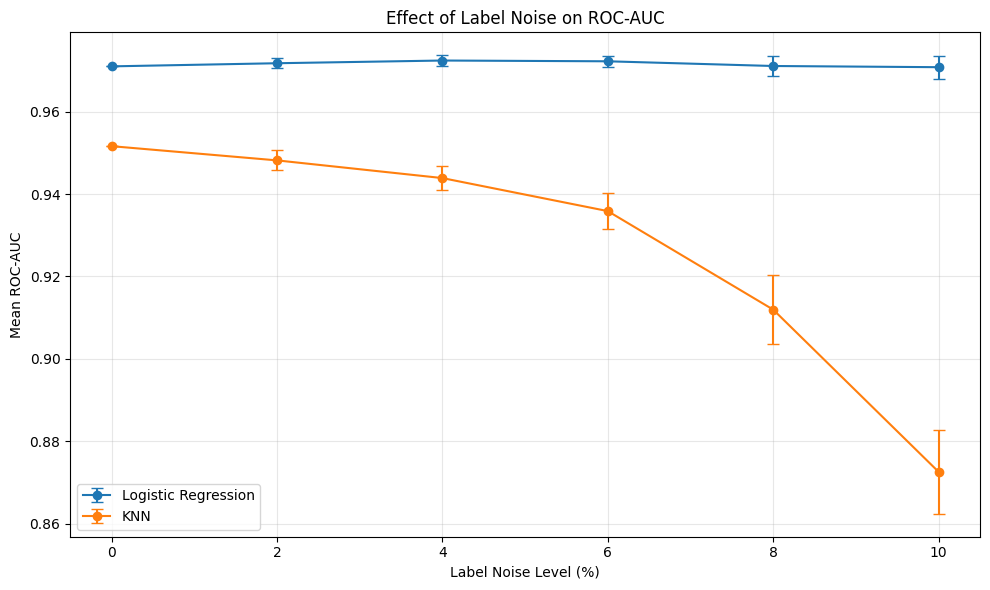

In [ ]:
# ============================================================
# 16. F1 DEGRADATION
# ============================================================
degradation_summary = (
    flat_summary
    .merge(
        baseline_f1,
        on="Model",
        how="left"
    )
)

degradation_summary[
    "F1_Degradation_Percent"
] = (
    (
        degradation_summary[
            "Baseline_F1"
        ]
        -
        degradation_summary[
            "F1_Mean"
        ]
    )
    /
    degradation_summary[
        "Baseline_F1"
    ]
    * 100
)


print("\n" + "=" * 80)
print("[16] RELATIVE F1 DEGRADATION")
print("=" * 80)

display(
    degradation_summary
    .sort_values(
        [
            "Noise_Type",
            "Noise_Level",
            "Model"
        ]
    )
    [
        [
            "Noise_Type",
            "Noise_Percentage",
            "Model",
            "Baseline_F1",
            "F1_Mean",
            "F1_SD",
            "F1_Degradation_Percent"
        ]
    ]
    .round(4)
)


# ============================================================
# 19. GRAPH 1
# FEATURE NOISE → F1
# ============================================================

plt.figure(
    figsize=(10, 6)
)

for model_name in models.keys():

    data = flat_summary[
        (
            flat_summary[
                "Noise_Type"
            ]
            == "Feature Noise"
        )
        &
        (
            flat_summary[
                "Model"
            ]
            == model_name
        )
    ].sort_values(
        "Noise_Level"
    )

    plt.errorbar(
        data[
            "Noise_Percentage"
        ],
        data[
            "F1_Mean"
        ],
        yerr=data[
            "F1_SD"
        ],
        marker="o",
        capsize=4,
        label=model_name
    )

plt.xlabel(
    "Feature Noise Level (%)"
)

plt.ylabel(
    "Mean F1 Score"
)

plt.title(
    "Effect of Feature Noise on Generalization"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 20. GRAPH 2
# LABEL NOISE → F1
# ============================================================

plt.figure(
    figsize=(10, 6)
)

for model_name in models.keys():

    data = flat_summary[
        (
            flat_summary[
                "Noise_Type"
            ]
            == "Label Noise"
        )
        &
        (
            flat_summary[
                "Model"
            ]
            == model_name
        )
    ].sort_values(
        "Noise_Level"
    )

    plt.errorbar(
        data[
            "Noise_Percentage"
        ],
        data[
            "F1_Mean"
        ],
        yerr=data[
            "F1_SD"
        ],
        marker="o",
        capsize=4,
        label=model_name
    )

plt.xlabel(
    "Label Noise Level (%)"
)

plt.ylabel(
    "Mean F1 Score"
)

plt.title(
    "Effect of Label Noise on Generalization"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 21. GRAPH 3
# FEATURE NOISE VS LABEL NOISE
# ============================================================

plt.figure(
    figsize=(11, 7)
)

for model_name in models.keys():

    feature_data = flat_summary[
        (
            flat_summary[
                "Noise_Type"
            ]
            == "Feature Noise"
        )
        &
        (
            flat_summary[
                "Model"
            ]
            == model_name
        )
    ].sort_values(
        "Noise_Level"
    )

    label_data = flat_summary[
        (
            flat_summary[
                "Noise_Type"
            ]
            == "Label Noise"
        )
        &
        (
            flat_summary[
                "Model"
            ]
            == model_name
        )
    ].sort_values(
        "Noise_Level"
    )

    plt.plot(
        feature_data[
            "Noise_Percentage"
        ],
        feature_data[
            "F1_Mean"
        ],
        marker="o",
        label=(
            f"{model_name} - "
            f"Feature Noise"
        )
    )

    plt.plot(
        label_data[
            "Noise_Percentage"
        ],
        label_data[
            "F1_Mean"
        ],
        marker="x",
        linestyle="--",
        label=(
            f"{model_name} - "
            f"Label Noise"
        )
    )

plt.xlabel(
    "Noise Level (%)"
)

plt.ylabel(
    "Mean F1 Score"
)

plt.title(
    "Feature Noise vs Label Noise"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 22. GRAPH 4
# RELATIVE F1 DEGRADATION
# ============================================================

plt.figure(
    figsize=(11, 7)
)

for model_name in models.keys():

    for noise_type, linestyle, marker in [

        (
            "Feature Noise",
            "-",
            "o"
        ),

        (
            "Label Noise",
            "--",
            "x"
        )
    ]:

        data = degradation_summary[
            (
                degradation_summary[
                    "Noise_Type"
                ]
                == noise_type
            )
            &
            (
                degradation_summary[
                    "Model"
                ]
                == model_name
            )
        ].sort_values(
            "Noise_Level"
        )

        plt.plot(
            data[
                "Noise_Percentage"
            ],
            data[
                "F1_Degradation_Percent"
            ],
            linestyle=linestyle,
            marker=marker,
            label=(
                f"{model_name} - "
                f"{noise_type}"
            )
        )

plt.axhline(
    0,
    linestyle=":"
)

plt.xlabel(
    "Noise Level (%)"
)

plt.ylabel(
    "F1 Degradation (%)"
)

plt.title(
    "Relative F1 Degradation Under Noise"
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 23. GRAPH 5
# FEATURE NOISE → ROC-AUC
# ============================================================

plt.figure(
    figsize=(10, 6)
)

for model_name in models.keys():

    data = flat_summary[
        (
            flat_summary[
                "Noise_Type"
            ]
            == "Feature Noise"
        )
        &
        (
            flat_summary[
                "Model"
            ]
            == model_name
        )
    ].sort_values(
        "Noise_Level"
    )

    plt.errorbar(
        data[
            "Noise_Percentage"
        ],
        data[
            "ROC_AUC_Mean"
        ],
        yerr=data[
            "ROC_AUC_SD"
        ],
        marker="o",
        capsize=4,
        label=model_name
    )

plt.xlabel(
    "Feature Noise Level (%)"
)

plt.ylabel(
    "Mean ROC-AUC"
)

plt.title(
    "Effect of Feature Noise on ROC-AUC"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 24. GRAPH 6
# LABEL NOISE → ROC-AUC
# ============================================================

plt.figure(
    figsize=(10, 6)
)

for model_name in models.keys():

    data = flat_summary[
        (
            flat_summary[
                "Noise_Type"
            ]
            == "Label Noise"
        )
        &
        (
            flat_summary[
                "Model"
            ]
            == model_name
        )
    ].sort_values(
        "Noise_Level"
    )

    plt.errorbar(
        data[
            "Noise_Percentage"
        ],
        data[
            "ROC_AUC_Mean"
        ],
        yerr=data[
            "ROC_AUC_SD"
        ],
        marker="o",
        capsize=4,
        label=model_name
    )

plt.xlabel(
    "Label Noise Level (%)"
)

plt.ylabel(
    "Mean ROC-AUC"
)

plt.title(
    "Effect of Label Noise on ROC-AUC"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# 17. 10% FEATURE-NOISE vs LABEL-NOISE COMPARISON
# ============================================================

comparison_10 = degradation_summary[
    degradation_summary["Noise_Percentage"] == 10
][[
    "Noise_Type", "Model", "Baseline_F1", "F1_Mean",
    "F1_SD", "F1_Degradation_Percent",
    "Recall_Mean", "ROC_AUC_Mean"
]].sort_values(["Model", "Noise_Type"])

display(comparison_10.round(4))

comparison_pivot = comparison_10.pivot(
    index="Model", columns="Noise_Type",
    values="F1_Degradation_Percent"
).reset_index()

comparison_pivot["Additional_Label_Degradation"] = (
    comparison_pivot["Label Noise"]
    - comparison_pivot["Feature Noise"]
)

display(comparison_pivot.round(4))

,Noise_Type,Model,Baseline_F1,F1_Mean,F1_SD,F1_Degradation_Percent,Recall_Mean,ROC_AUC_Mean
6,Feature Noise,KNN,0.8882,0.8874,0.0037,0.0893,0.8433,0.9483
24,Label Noise,KNN,0.8882,0.4717,0.0331,46.8880,0.3195,0.8725
7,Feature Noise,Logistic Regression,0.8813,0.8790,0.0010,0.2667,0.8180,0.9708
25,Label Noise,Logistic Regression,0.8813,0.3387,0.0433,61.5735,0.2046,0.9708


Noise_Type,Model,Feature Noise,Label Noise,Additional_Label_Degradation
0,KNN,0.0893,46.8880,46.7987
1,Logistic Regression,0.2667,61.5735,61.3068


In [ ]:
# ============================================================
# 18. LABEL-NOISE TRANSITION DIAGNOSTIC
# ============================================================

TRANSITION_NOISE_LEVELS = [0.06, 0.08, 0.085, 0.09, 0.095, 0.10]
TRANSITION_REPETITIONS = 10

transition_results = []

total_runs = (
    len(TRANSITION_NOISE_LEVELS)
    * TRANSITION_REPETITIONS
    * len(models)
)
run_number = 0

print("=" * 70)
print("LABEL-NOISE TRANSITION DIAGNOSTIC")
print("=" * 70)
print(
    "Noise levels:",
    [f"{x*100:g}%" for x in TRANSITION_NOISE_LEVELS]
)
print(f"Repetitions: {TRANSITION_REPETITIONS}")
print(f"Models: {list(models.keys())}")
print(f"Total model trainings: {total_runs}")
print("=" * 70)

for noise_level in TRANSITION_NOISE_LEVELS:

    print(f"\n{'=' * 70}")
    print(f"TRANSITION LEVEL: {noise_level * 100:g}%")
    print(f"{'=' * 70}")

    for repetition in range(TRANSITION_REPETITIONS):

        seed = RANDOM_STATE + repetition + int(noise_level * 10000)

        print(
            f"\n  Repetition {repetition + 1}/{TRANSITION_REPETITIONS} "
            f"| Seed: {seed}"
        )

        y_train_noisy = add_symmetric_label_noise(
            y_train,
            noise_level,
            random_state=seed
        )

        changed = y_train_noisy.values != y_train.values
        actual_flipped = changed.sum()

        original_pulsars = y_train.values == 1
        pulsar_count = original_pulsars.sum()
        pulsars_flipped = (changed & original_pulsars).sum()
        pulsars_surviving = pulsar_count - pulsars_flipped

        print(
            f"  Labels changed: {actual_flipped}/{len(y_train)} "
            f"({actual_flipped / len(y_train) * 100:.2f}%)"
        )
        print(
            f"  Original pulsars: {pulsar_count} | "
            f"Surviving: {pulsars_surviving} | "
            f"Survival: {pulsars_surviving / pulsar_count * 100:.2f}%"
        )

        for model_name, model in models.items():

            run_number += 1
            print(
                f"    [{run_number}/{total_runs}] "
                f"Training {model_name}..."
            )

            results = evaluate_model(
                model,
                X_train,
                y_train_noisy,
                X_test,
                y_test
            )

            predictions = model.predict(X_test)

            tn, fp, fn, tp = confusion_matrix(
                y_test,
                predictions,
                labels=[0, 1]
            ).ravel()

            transition_results.append({
                "Noise_Type": "Label Noise",
                "Noise_Percentage": noise_level * 100,
                "Noise_Level": noise_level,
                "Repetition": repetition + 1,
                "Seed": seed,
                "Model": model_name,
                "Actual_Flipped": actual_flipped,
                "Original_Pulsar_Count": pulsar_count,
                "Pulsars_Flipped": pulsars_flipped,
                "Pulsars_Surviving": pulsars_surviving,
                "Pulsar_Survival_%": pulsars_surviving / pulsar_count * 100,
                "Pulsar_Flip_%": pulsars_flipped / pulsar_count * 100,
                "True_Negatives": tn,
                "False_Positives": fp,
                "False_Negatives": fn,
                "True_Positives": tp,
                "Predicted_Positive": int(fp + tp),
                "Predicted_Negative": int(tn + fn),
                **results
            })

            print(
                f"    ✓ {model_name} completed | "
                f"F1={results['F1']:.4f} | "
                f"Recall={results['Recall']:.4f} | "
                f"ROC-AUC={results['ROC-AUC']:.4f}"
            )

        print(
            f"  ✓ Repetition {repetition + 1}/"
            f"{TRANSITION_REPETITIONS} completed"
        )

transition_results_df = pd.DataFrame(transition_results)

print("\n" + "=" * 70)
print("TRANSITION DIAGNOSTIC COMPLETED")
print("=" * 70)
print(f"Rows generated: {len(transition_results_df)}")
print(f"Expected rows: {total_runs}")
print("=" * 70)

LABEL-NOISE TRANSITION DIAGNOSTIC
Noise levels: ['6%', '8%', '8.5%', '9%', '9.5%', '10%']
Repetitions: 10
Models: ['Logistic Regression', 'KNN']
Total model trainings: 120

TRANSITION LEVEL: 6%

  Repetition 1/10 | Seed: 642
  Labels changed: 858/14318 (5.99%)
  Original pulsars: 1311 | Surviving: 882 | Survival: 67.28%
    [1/120] Training Logistic Regression...
    ✓ Logistic Regression completed | F1=0.7617 | Recall=0.6189 | ROC-AUC=0.9733
    [2/120] Training KNN...
    ✓ KNN completed | F1=0.7650 | Recall=0.6402 | ROC-AUC=0.9381
  ✓ Repetition 1/10 completed

  Repetition 2/10 | Seed: 643
  Labels changed: 858/14318 (5.99%)
  Original pulsars: 1311 | Surviving: 882 | Survival: 67.28%
    [3/120] Training Logistic Regression...
    ✓ Logistic Regression completed | F1=0.7640 | Recall=0.6220 | ROC-AUC=0.9693
    [4/120] Training KNN...
    ✓ KNN completed | F1=0.7569 | Recall=0.6311 | ROC-AUC=0.9358
  ✓ Repetition 2/10 completed

  Repetition 3/10 | Seed: 644
  Labels changed: 858/1

In [ ]:
# ============================================================
# 19. TRANSITION SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("[19] LABEL-NOISE TRANSITION SUMMARY")
print("=" * 80)


transition_summary = (
    transition_results_df
    .groupby(
        [
            "Noise_Percentage",
            "Model"
        ]
    )
    .agg(

        F1_Mean=(
            "F1",
            "mean"
        ),

        F1_SD=(
            "F1",
            "std"
        ),

        Precision_Mean=(
            "Precision",
            "mean"
        ),

        Precision_SD=(
            "Precision",
            "std"
        ),

        Recall_Mean=(
            "Recall",
            "mean"
        ),

        Recall_SD=(
            "Recall",
            "std"
        ),

        ROC_AUC_Mean=(
            "ROC-AUC",
            "mean"
        ),

        ROC_AUC_SD=(
            "ROC-AUC",
            "std"
        ),

        Accuracy_Mean=(
            "Accuracy",
            "mean"
        ),

        Accuracy_SD=(
            "Accuracy",
            "std"
        ),

        Predicted_Positive_Mean=(
            "Predicted_Positive",
            "mean"
        ),

        Predicted_Positive_SD=(
            "Predicted_Positive",
            "std"
        ),

        Pulsar_Survival_Mean=(
            "Pulsar_Survival_%",
            "mean"
        ),

        Pulsar_Flip_Mean=(
            "Pulsar_Flip_%",
            "mean"
        )

    )
    .reset_index()
)


display(
    transition_summary
    .round(4)
)


[19] LABEL-NOISE TRANSITION SUMMARY


,Noise_Percentage,Model,F1_Mean,F1_SD,Precision_Mean,Precision_SD,Recall_Mean,Recall_SD,ROC_AUC_Mean,ROC_AUC_SD,Accuracy_Mean,Accuracy_SD,Predicted_Positive_Mean,Predicted_Positive_SD,Pulsar_Survival_Mean,Pulsar_Flip_Mean
0,6.0,KNN,0.7686,0.0101,0.9462,0.0102,0.6473,0.0138,0.9359,0.0044,0.9643,0.0013,224.4,5.5817,67.2769,32.7231
1,6.0,Logistic Regression,0.7669,0.0051,0.9908,0.0027,0.6256,0.0070,0.9722,0.0013,0.9652,0.0006,207.1,2.5144,67.2769,32.7231
2,8.0,KNN,0.6317,0.0167,0.9388,0.0158,0.4762,0.0172,0.9119,0.0083,0.9492,0.0019,166.4,5.8157,56.3692,43.6308
3,8.0,Logistic Regression,0.6275,0.0121,1.0000,0.0000,0.4573,0.0128,0.9711,0.0025,0.9503,0.0012,150.0,4.1899,56.3692,43.6308
4,8.5,KNN,0.5983,0.0326,0.9372,0.0154,0.4399,0.0328,0.9019,0.0075,0.9460,0.0033,153.9,9.9939,53.6232,46.3768
5,8.5,Logistic Regression,0.5812,0.0152,1.0000,0.0000,0.4098,0.0150,0.9705,0.0025,0.9459,0.0014,134.4,4.9261,53.6232,46.3768
6,9.0,KNN,0.5755,0.0303,0.9314,0.0161,0.4171,0.0314,0.8960,0.0080,0.9438,0.0028,146.9,11.2788,50.8772,49.1228
7,9.0,Logistic Regression,0.5274,0.0129,1.0000,0.0000,0.3582,0.0119,0.9707,0.0023,0.9412,0.0011,117.5,3.8944,50.8772,49.1228
8,9.5,KNN,0.5122,0.0287,0.9101,0.0179,0.3567,0.0259,0.8844,0.0103,0.9378,0.0026,128.5,7.9477,48.1312,51.8688
9,9.5,Logistic Regression,0.4571,0.0289,1.0000,0.0000,0.2966,0.0240,0.9711,0.0022,0.9356,0.0022,97.3,7.8747,48.1312,51.8688



[20] CONFUSION MATRIX ANALYSIS


,Noise_Percentage,Model,True_Negatives,False_Positives,False_Negatives,True_Positives,Predicted_Positive,Predicted_Negative
0,6.0,KNN,3239.9,12.1,115.7,212.3,224.4,3355.6
1,6.0,Logistic Regression,3250.1,1.9,122.8,205.2,207.1,3372.9
2,8.0,KNN,3241.8,10.2,171.8,156.2,166.4,3413.6
3,8.0,Logistic Regression,3252.0,0.0,178.0,150.0,150.0,3430.0
4,8.5,KNN,3242.4,9.6,183.7,144.3,153.9,3426.1
5,8.5,Logistic Regression,3252.0,0.0,193.6,134.4,134.4,3445.6
6,9.0,KNN,3241.9,10.1,191.2,136.8,146.9,3433.1
7,9.0,Logistic Regression,3252.0,0.0,210.5,117.5,117.5,3462.5
8,9.5,KNN,3240.5,11.5,211.0,117.0,128.5,3451.5
9,9.5,Logistic Regression,3252.0,0.0,230.7,97.3,97.3,3482.7


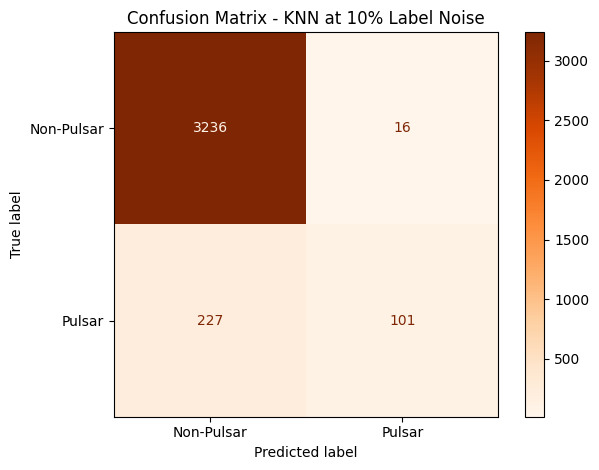

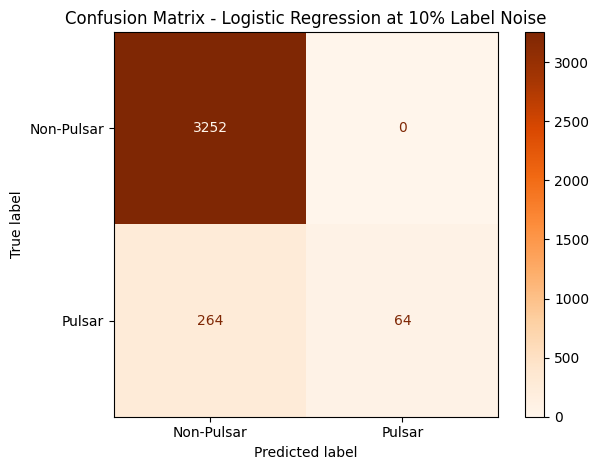

✓ Confusion-matrix figures saved (KNN and Logistic Regression).


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# ============================================================
# 20. CONFUSION-MATRIX ANALYSIS
# ============================================================

print("\n" + "=" * 80)
print("[20] CONFUSION MATRIX ANALYSIS")
print("=" * 80)

confusion_summary = (
    transition_results_df
    .groupby(["Noise_Percentage", "Model"])[
        [
            "True_Negatives",
            "False_Positives",
            "False_Negatives",
            "True_Positives",
            "Predicted_Positive",
            "Predicted_Negative"
        ]
    ]
    .mean()
    .reset_index()
)

display(confusion_summary.round(2))

# Standard 2x2 confusion-matrix figures used in class.
# Use already recorded 10% label-noise runs (repetition 1), so no new training is needed.
cm_models = [
    ("KNN", "confusion_matrix_knn_10pct_label_noise.png"),
    ("Logistic Regression", "confusion_matrix_logreg_10pct_label_noise.png"),
]

for model_name, filename in cm_models:
    cm_row = transition_results_df[
        (transition_results_df["Noise_Percentage"] == 10.0) &
        (transition_results_df["Model"] == model_name) &
        (transition_results_df["Repetition"] == 1)
    ].iloc[0]

    cm = np.array([
        [cm_row["True_Negatives"], cm_row["False_Positives"]],
        [cm_row["False_Negatives"], cm_row["True_Positives"]]
    ])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-Pulsar", "Pulsar"]
    )

    disp.plot(cmap="Oranges")
    plt.title(f"Confusion Matrix - {model_name} at 10% Label Noise")
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

print("✓ Confusion-matrix figures saved (KNN and Logistic Regression).")


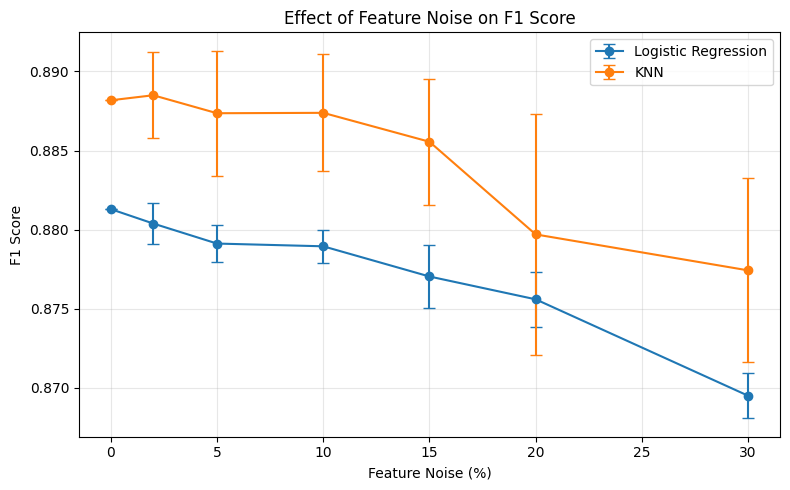

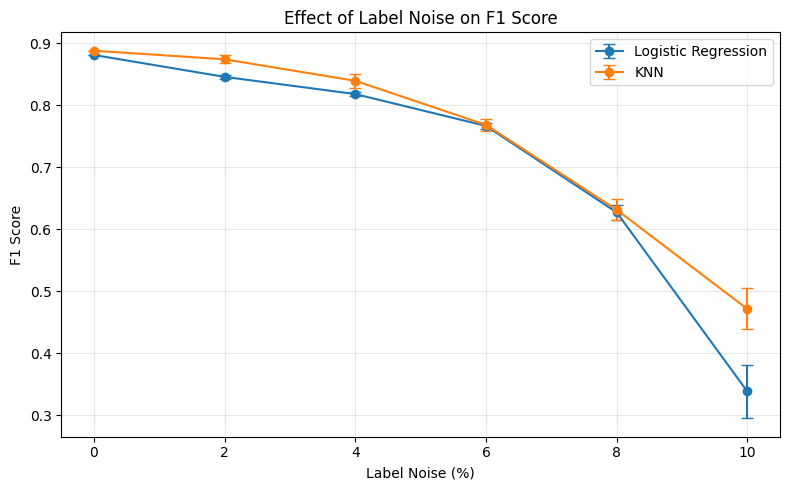

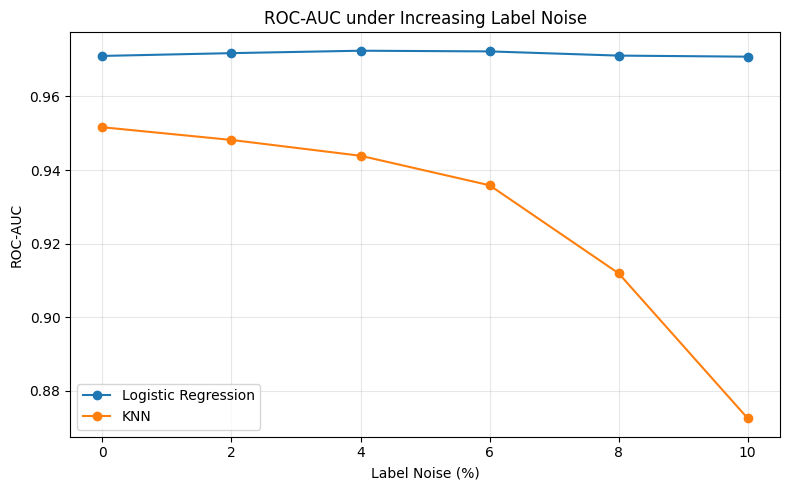

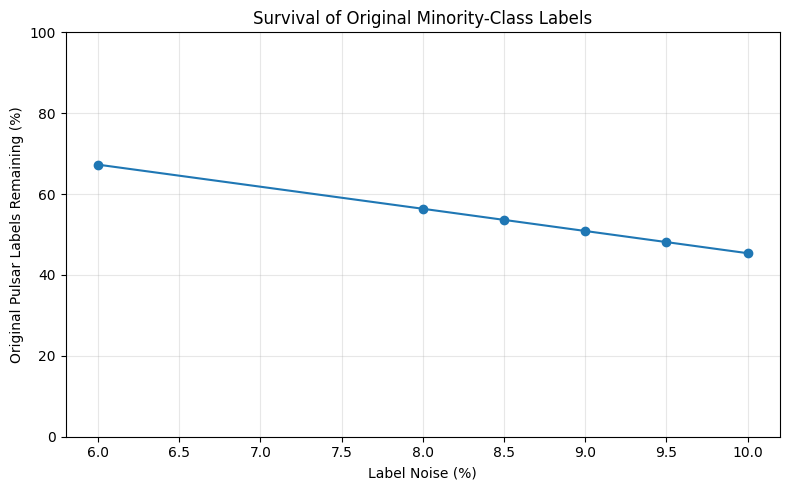

✓ Four main figures saved.


In [ ]:
# ============================================================
# 21. FINAL FIGURES
# ============================================================
# No additional model training is performed here.

# 21. Feature-noise F1
plt.figure(figsize=(8, 5))
for model in models:
    d = feature_summary[feature_summary["Model"] == model].sort_values("Noise_Percentage")
    plt.errorbar(d["Noise_Percentage"], d["F1_Mean"], yerr=d["F1_SD"],
                 marker="o", capsize=4, label=model)
plt.xlabel("Feature Noise (%)")
plt.ylabel("F1 Score")
plt.title("Effect of Feature Noise on F1 Score")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_noise_f1.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Label-noise F1
plt.figure(figsize=(8, 5))
for model in models:
    d = label_summary[label_summary["Model"] == model].sort_values("Noise_Percentage")
    plt.errorbar(d["Noise_Percentage"], d["F1_Mean"], yerr=d["F1_SD"],
                 marker="o", capsize=4, label=model)
plt.xlabel("Label Noise (%)")
plt.ylabel("F1 Score")
plt.title("Effect of Label Noise on F1 Score")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(FIGURES_DIR / "label_noise_f1.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Label-noise ROC-AUC
plt.figure(figsize=(8, 5))
for model in models:
    d = label_summary[label_summary["Model"] == model].sort_values("Noise_Percentage")
    plt.plot(d["Noise_Percentage"], d["ROC_AUC_Mean"], marker="o", label=model)
plt.xlabel("Label Noise (%)")
plt.ylabel("ROC-AUC")
plt.title("ROC-AUC under Increasing Label Noise")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig(FIGURES_DIR / "label_noise_auc.png", dpi=300, bbox_inches="tight")
plt.show()

# 4. Original minority-class (pulsar) label survival
survival = transition_summary.groupby("Noise_Percentage")["Pulsar_Survival_Mean"].first().reset_index()
plt.figure(figsize=(8, 5))
plt.plot(survival["Noise_Percentage"], survival["Pulsar_Survival_Mean"], marker="o")
plt.xlabel("Label Noise (%)")
plt.ylabel("Original Pulsar Labels Remaining (%)")
plt.title("Survival of Original Minority-Class Labels")
plt.ylim(0, 100); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(FIGURES_DIR / "pulsar_survival.png", dpi=300, bbox_inches="tight")
plt.show()

print("✓ Four main figures saved.")

## 24. Conclusion

Under the tested conditions, **label noise harms generalization much more strongly than feature noise**. Feature noise produces a relatively mild decline in F1, while label noise causes substantial losses, especially in the 8–10% transition region. The minority-class survival and confusion-matrix evidence support the explanation that corrupted labels increasingly damage the learnable pulsar signal.

This conclusion is specific to HTRU2, Logistic Regression, KNN, the fixed clean test set, and the controlled noise mechanisms used here.

In [ ]:
# ============================================================
# 26. SAVE RAW EXPERIMENTAL RESULTS
# ============================================================
all_results_df.to_csv(
    RESULTS_DIR / "htru2_experiment2_all_results.csv",
    index=False
)

feature_results_df.to_csv(
    RESULTS_DIR / "htru2_experiment2_feature_noise.csv",
    index=False
)

label_results_df.to_csv(
    RESULTS_DIR / "htru2_experiment2_label_noise.csv",
    index=False
)

In [ ]:
# ============================================================
# 27. SAVE SUMMARY RESULTS
# ============================================================
flat_summary.to_csv(
    RESULTS_DIR / "htru2_experiment2_summary.csv",
    index=False
)

degradation_summary.to_csv(
    RESULTS_DIR / "htru2_experiment2_degradation.csv",
    index=False
)

baseline_df.to_csv(
    RESULTS_DIR / "htru2_experiment2_baseline.csv",
    index=False
)